In [ ]:

# CHURRO-CARE - Step 1
# Checking our computer

import torch

print("Hello! CHURRO-CARE project started.")

if torch.cuda.is_available():
    print("GPU is ready!")
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available.")


Hello! CHURRO-CARE project started.
GPU is not available.


In [ ]:

# CHURRO-CARE - Installing Libraries

!pip install opencv-python-headless pillow pandas jiwer rapidfuzz


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 38.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jiwer]


In [ ]:

# CHURRO-CARE - Creating Project Folders

import os

folders = [
    "data/original",
    "data/processed",
    "results",
    "outputs"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("All project folders created successfully!")

print("\nProject folders:")
for folder in folders:
    print("📁", folder)


All project folders created successfully!

Project folders:
📁 data/original
📁 data/processed
📁 results
📁 outputs


In [4]:

# CHURRO-CARE - Download Dataset

from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="stanford-oval/churro-dataset",
    repo_type="dataset"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 109 files:   0%|          | 0/109 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
!pip install huggingface_hub

In [ ]:

# CHURRO-CARE - Read a small dataset sample

!pip install -q datasets


In [ ]:

from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="stanford-oval/churro-dataset",
    repo_type="dataset"
)

print("Total files:", len(files))

print("\nFirst 20 files:")
for file in files[:20]:
    print(file)


In [ ]:

from datasets import load_dataset

# Read dataset in streaming mode
dataset = load_dataset(
    "stanford-oval/churro-dataset",
    split="dev",
    streaming=True
)

# Take only ONE sample
sample = next(iter(dataset))

print("Sample loaded successfully!")
print("\nAvailable fields:")
print(sample.keys())

print("\nSample details:")
for key, value in sample.items():
    if key != "image":
        print(key, ":", str(value)[:500])


In [ ]:

# CHURRO-CARE - Display Sample Image

from IPython.display import display

image = sample["image"]

print("Image type:", type(image))
print("Image size:", image.size)

display(image)


In [ ]:

# CHURRO-CARE - Save Original Image

import os

os.makedirs("data/original", exist_ok=True)

image.save("data/original/sample.png")

print("Image saved successfully!")
print("Location: data/original/sample.png")



In [ ]:

# CHURRO-CARE - Image Preprocessing Experiment

import cv2
import os
import matplotlib.pyplot as plt

# Create folders
os.makedirs("data/processed", exist_ok=True)

# Load original image
original = cv2.imread("data/original/sample.png")

# Convert to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# METHOD 1: Original image
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# METHOD 2: Contrast enhancement (CLAHE)
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

contrast = clahe.apply(gray)

# METHOD 3: Denoising + Thresholding
denoised = cv2.fastNlMeansDenoising(
    contrast,
    None,
    10,
    7,
    21
)

thresholded = cv2.adaptiveThreshold(
    denoised,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    10
)

# Save all images
cv2.imwrite("data/processed/original.png", original)
cv2.imwrite("data/processed/contrast.png", contrast)
cv2.imwrite("data/processed/denoised_threshold.png", thresholded)

print("All 3 image versions created successfully!")

# Display comparison
plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(contrast, cmap="gray")
plt.title("Contrast Enhanced")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(thresholded, cmap="gray")
plt.title("Denoised + Thresholded")
plt.axis("off")

plt.show()


In [ ]:

!pip install -q uv


In [ ]:

!uv tool install churro-ocr



In [ ]:

import os

os.environ["PATH"] += ":/root/.local/bin"

print("CHURRO path configured successfully!")


In [ ]:

!churro-ocr install hf


In [ ]:
!churro-ocr transcribe --image data/original/sample.png --backend hf --model stanford-oval/churro-3B

In [ ]:
!pip install -q accelerate

In [ ]:
!churro-ocr transcribe --image data/original/sample.png --backend hf --model stanford-oval/churro-3B

In [ ]:
!uv tool inject churro-ocr accelerate

In [ ]:
!uv tool install --with accelerate --force churro-ocr

In [ ]:
!churro-ocr transcribe --image data/original/sample.png --backend hf --model stanford-oval/churro-3B


In [ ]:
!uv tool install --with accelerate --with qwen-vl-utils --with transformers --force churro-ocr

In [ ]:
!churro-ocr install hf

In [ ]:
!churro-ocr transcribe --image data/original/sample.png --backend hf --model stanford-oval/churro-3B

In [ ]:
!nvidia-smi

In [ ]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("BF16 supported:", torch.cuda.is_bf16_supported())

In [ ]:
from PIL import Image

img = Image.open("data/original/sample.png")

# Keep the page shape, but make its longest side 1024 pixels
img.thumbnail((1024, 1024))

img.save("data/original/sample_small.png")

print("New image size:", img.size)
print("Saved as: data/original/sample_small.png")

In [ ]:
!churro-ocr transcribe --image data/original/sample_small.png --backend hf --model stanford-oval/churro-3B

In [ ]:
ocr_text = """<HistoricalDocument xmlns="http://example.com/historicaldocument">
<Metadata>
<Language>Czech</Language>
<WritingDirection>ltr</WritingDirection>
<PhysicalDescription>Printed book page, single column.</PhysicalDescription>
<Description>Narrative text from a historical Czech book, likely 18th or 19th century.</Description>
<Script>Latin</Script>
</Metadata>
<Page>
<Body>
<Paragraph>
<Line>tobě, bys wjce ke mně nechodila. Fi-</Line>
<Line>netta wzala na to Odpuſſtěnj, potom</Line>
<Line>gi Merluſſe gednu malau Sſkatuli,</Line>
<Line>ktecá za třikrát y čtyrykrát jto Tiſýc</Line>
<Line>Tolarů ſtala, od Diamantu darowa-</Line>
<Line>la, a byla zas od toho ſſpaňhelſkého</Line>
<Line>Koně dlé Obyčege ſpatky doneſſena.</Line>
</Paragraph>
</Body>
</Page>
</HistoricalDocument>"""

with open("outputs/ocr_result.txt", "w", encoding="utf-8") as f:
    f.write(ocr_text)

print("OCR result saved successfully!")

In [ ]:
import os
os.makedirs("outputs", exist_ok=True)
with open("outputs/ocr_result.txt", "w", encoding="utf-8") as f:
    f.write(ocr_text)

print("OCR result saved successfully!")

In [ ]:
with open("outputs/ocr_result.txt", "r", encoding="utf-8") as f:
    print(f.read()[:1000])

In [ ]:
reference_text = sample["cleaned_transcription"]

print("REFERENCE TEXT:")
print(reference_text[:1000])

In [ ]:
from jiwer import cer, wer
from rapidfuzz.distance import Levenshtein

# Read OCR output
with open("outputs/ocr_result.txt", "r", encoding="utf-8") as f:
    ocr_text = f.read()

# Reference transcription
reference_text = sample["cleaned_transcription"]

# Calculate metrics
CER = cer(reference_text, ocr_text)
WER = wer(reference_text, ocr_text)

NLS = Levenshtein.normalized_similarity(
    reference_text,
    ocr_text
)

print("CER:", round(CER, 4))
print("WER:", round(WER, 4))
print("NLS:", round(NLS, 4))

In [ ]:
!pip install -q jiwer rapidfuzz

In [ ]:
from jiwer import cer, wer
from rapidfuzz.distance import Levenshtein

with open("outputs/ocr_result.txt", "r", encoding="utf-8") as f:
    ocr_text = f.read()

reference_text = sample["cleaned_transcription"]

CER = cer(reference_text, ocr_text)
WER = wer(reference_text, ocr_text)
NLS = Levenshtein.normalized_similarity(reference_text, ocr_text)

print("Character Error Rate (CER):", round(CER, 4))
print("Word Error Rate (WER):", round(WER, 4))
print("Normalized Levenshtein Similarity (NLS):", round(NLS, 4))

In [ ]:
print("Reference text length:", len(reference_text))
print("OCR text length:", len(ocr_text))

In [ ]:
!churro-ocr transcribe --image data/original/sample_small.png --backend hf --model stanford-oval/churro-3B > outputs/ocr_result_full.txt

In [ ]:
with open("outputs/ocr_result_full.txt", "r", encoding="utf-8") as f:
    full_ocr_text = f.read()

print("Full OCR text length:", len(full_ocr_text))
print("\nFirst 500 characters:\n")
print(full_ocr_text[:500])

In [ ]:
import re
import html

# Remove escaped formatting if present
clean_xml = full_ocr_text.replace("\\<", "<")

# Extract only the Body section
body_match = re.search(
    r"<Body>(.*?)</Body>",
    clean_xml,
    re.DOTALL
)

if body_match:
    body_text = body_match.group(1)

    # Remove XML tags
    body_text = re.sub(r"<[^>]+>", " ", body_text)

    # Decode XML entities
    body_text = html.unescape(body_text)

    # Normalize whitespace
    body_text = re.sub(r"\s+", " ", body_text).strip()

    print("Extracted OCR text length:", len(body_text))
    print("\nExtracted OCR text:\n")
    print(body_text[:1000])
else:
    print("Body section not found. Please show me the output.")

In [ ]:
from jiwer import cer, wer
from rapidfuzz.distance import Levenshtein

reference_text = sample["cleaned_transcription"]

CER = cer(reference_text, body_text)
WER = wer(reference_text, body_text)
NLS = Levenshtein.normalized_similarity(reference_text, body_text)

print("Character Error Rate (CER):", round(CER, 4))
print("Word Error Rate (WER):", round(WER, 4))
print("Normalized Levenshtein Similarity (NLS):", round(NLS, 4))

In [ ]:
!churro-ocr transcribe --image data/processed/contrast.png --backend hf --model stanford-oval/churro-3B > outputs/contrast_result.txt

In [ ]:
from PIL import Image

img = Image.open("data/processed/contrast.png")

img.thumbnail((1024, 1024))

img.save("data/processed/contrast_small.png")

print("New contrast image size:", img.size)

In [ ]:
!churro-ocr transcribe --image data/processed/contrast_small.png --backend hf --model stanford-oval/churro-3B > outputs/contrast_result_full.txt

In [ ]:
import os

print("File exists:", os.path.exists("outputs/contrast_result_full.txt"))
print("File size:", os.path.getsize("outputs/contrast_result_full.txt"), "bytes")

In [ ]:
import re
import html

with open("outputs/contrast_result_full.txt", "r", encoding="utf-8") as f:
    contrast_xml = f.read()

contrast_xml = contrast_xml.replace("\\<", "<")

body_match = re.search(
    r"<Body>(.*?)</Body>",
    contrast_xml,
    re.DOTALL
)

if body_match:
    contrast_text = body_match.group(1)
    contrast_text = re.sub(r"<[^>]+>", " ", contrast_text)
    contrast_text = html.unescape(contrast_text)
    contrast_text = re.sub(r"\s+", " ", contrast_text).strip()

    print("Contrast OCR text length:", len(contrast_text))
    print("\nPreview:\n")
    print(contrast_text[:1000])
else:
    print("Body section not found.")

In [ ]:
from jiwer import cer, wer
from rapidfuzz.distance import Levenshtein

reference_text = sample["cleaned_transcription"]

contrast_CER = cer(reference_text, contrast_text)
contrast_WER = wer(reference_text, contrast_text)
contrast_NLS = Levenshtein.normalized_similarity(
    reference_text, contrast_text
)

print("Contrast CER:", round(contrast_CER, 4))
print("Contrast WER:", round(contrast_WER, 4))
print("Contrast NLS:", round(contrast_NLS, 4))

In [ ]:
from PIL import Image

img = Image.open("data/processed/denoised_threshold.png")

img.thumbnail((1024, 1024))

img.save("data/processed/denoised_threshold_small.png")

print("New denoised image size:", img.size)

In [ ]:
!churro-ocr transcribe --image data/processed/denoised_threshold_small.png --backend hf --model stanford-oval/churro-3B > outputs/denoised_result_full.txt

In [ ]:
import os

print("File exists:", os.path.exists("outputs/denoised_result_full.txt"))
print("File size:", os.path.getsize("outputs/denoised_result_full.txt"), "bytes")

In [ ]:
import re
import html

with open("outputs/denoised_result_full.txt", "r", encoding="utf-8") as f:
    denoised_xml = f.read()

denoised_xml = denoised_xml.replace("\\<", "<")

body_match = re.search(
    r"<Body>(.*?)</Body>",
    denoised_xml,
    re.DOTALL
)

if body_match:
    denoised_text = body_match.group(1)
    denoised_text = re.sub(r"<[^>]+>", " ", denoised_text)
    denoised_text = html.unescape(denoised_text)
    denoised_text = re.sub(r"\s+", " ", denoised_text).strip()

    print("Denoised OCR text length:", len(denoised_text))
    print("\nPreview:\n")
    print(denoised_text[:1000])
else:
    print("Body section not found.")

In [ ]:
from jiwer import cer, wer
from rapidfuzz.distance import Levenshtein

reference_text = sample["cleaned_transcription"]

denoised_CER = cer(reference_text, denoised_text)
denoised_WER = wer(reference_text, denoised_text)
denoised_NLS = Levenshtein.normalized_similarity(
    reference_text, denoised_text
)

print("Denoised CER:", round(denoised_CER, 4))
print("Denoised WER:", round(denoised_WER, 4))
print("Denoised NLS:", round(denoised_NLS, 4))

In [ ]:
import pandas as pd
import os

results = pd.DataFrame({
    "Method": [
        "Original Image",
        "Contrast Enhancement",
        "Denoising + Thresholding"
    ],
    "CER": [
        CER,
        contrast_CER,
        denoised_CER
    ],
    "WER": [
        WER,
        contrast_WER,
        denoised_WER
    ],
    "NLS": [
        NLS,
        contrast_NLS,
        denoised_NLS
    ]
})

os.makedirs("results", exist_ok=True)

results.to_csv("results/initial_metrics.csv", index=False)

print(results)
print("\nResults saved successfully!")

In [ ]:
import matplotlib.pyplot as plt

results.plot(
    x="Method",
    y=["CER", "WER", "NLS"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("CHURRO-CARE: OCR Evaluation Metrics")
plt.ylabel("Metric Score")
plt.xlabel("Preprocessing Method")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("results/initial_metrics_graph.png", dpi=300)

plt.show()

In [ ]:
print("Reference text length:", len(sample["cleaned_transcription"]))
print("Original OCR length:", len(original_text))
print("Contrast OCR length:", len(contrast_text))
print("Denoised OCR length:", len(denoised_text))

In [ ]:
print("Reference text length:", len(sample["cleaned_transcription"]))
print("Original OCR length:", len(original))
print("Contrast OCR length:", len(contrast_text))
print("Denoised OCR length:", len(denoised_text))

In [ ]:
print(original[:1000])

In [ ]:
print([name for name in globals() if "text" in name.lower()])

In [ ]:
print("Reference:", len(reference_text))
print("Original OCR:", len(ocr_text))
print("Contrast OCR:", len(contrast_text))
print("Denoised OCR:", len(denoised_text))

In [ ]:
print(ocr_text[:1000])

In [ ]:
import re
import html

ocr_text_clean = html.unescape(
    re.sub(r"<[^>]+>", " ", ocr_text)
)

ocr_text_clean = " ".join(ocr_text_clean.split())

print("Clean OCR length:", len(ocr_text_clean))
print(ocr_text_clean[:500])


In [ ]:
import re
import html

def extract_lines(xml_text):
    lines = re.findall(r"<Line>(.*?)</Line>", xml_text, flags=re.DOTALL)
    text = " ".join(html.unescape(line) for line in lines)
    return " ".join(text.split())

ocr_text_clean = extract_lines(ocr_text)
contrast_text_clean = extract_lines(full_ocr_text) if "full_ocr_text" in globals() else extract_lines(contrast_text)
denoised_text_clean = extract_lines(denoised_text)

print("Original:", len(ocr_text_clean))
print("Contrast:", len(contrast_text_clean))
print("Denoised:", len(denoised_text_clean))

In [ ]:
print(denoised_text[:1000])

In [ ]:
denoised_text_clean = " ".join(denoised_text.split())

print("Denoised clean length:", len(denoised_text_clean))
print(denoised_text_clean[:500])

In [ ]:
print(contrast_text[:1000])

In [ ]:
contrast_text_clean = " ".join(contrast_text.split())

print("Contrast clean length:", len(contrast_text_clean))
print(contrast_text_clean[:500])

In [ ]:
from jiwer import cer, wer
from rapidfuzz.distance import Levenshtein

reference = " ".join(reference_text.split())

results = pd.DataFrame([
    {
        "Method": "Original Image",
        "CER": cer(reference, ocr_text_clean),
        "WER": wer(reference, ocr_text_clean),
        "NLS": 1 - Levenshtein.normalized_distance(reference, ocr_text_clean)
    },
    {
        "Method": "Contrast Enhancement",
        "CER": cer(reference, contrast_text_clean),
        "WER": wer(reference, contrast_text_clean),
        "NLS": 1 - Levenshtein.normalized_distance(reference, contrast_text_clean)
    },
    {
        "Method": "Denoising + Thresholding",
        "CER": cer(reference, denoised_text_clean),
        "WER": wer(reference, denoised_text_clean),
        "NLS": 1 - Levenshtein.normalized_distance(reference, denoised_text_clean)
    }
])

print(results.round(4))
results.to_csv("results/initial_metrics.csv", index=False)

In [ ]:
import matplotlib.pyplot as plt

results.plot(
    x="Method",
    y=["CER", "WER", "NLS"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("CHURRO-CARE: OCR Evaluation Metrics")
plt.ylabel("Metric Score")
plt.xlabel("Preprocessing Method")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("results/initial_metrics_graph.png", dpi=300)
plt.show()

In [ ]:
print("Dataset sample details:")
print("Example ID:", sample["example_id"])
print("Document type:", sample["document_type"])
print("Language:", sample["main_language"])
print("Script:", sample["main_script"])

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "stanford-oval/churro-dataset",
    split="dev",
    streaming=True
)

samples = []

for item in dataset:
    if item["cleaned_transcription"] and item["image"]:
        samples.append(item)

    if len(samples) == 5:
        break

print("Total samples collected:", len(samples))

for i, item in enumerate(samples):
    print(
        i + 1,
        item["example_id"],
        item["main_language"],
        item["document_type"]
    )

In [ ]:
from IPython.display import display

display(samples[1]["image"])
print("Example ID:", samples[1]["example_id"])
print("Reference length:", len(samples[1]["cleaned_transcription"]))

In [ ]:
from PIL import Image

img2 = samples[1]["image"].convert("RGB")

img2.thumbnail((1024, 1024))

img2.save("data/original/sample2.png")

print("Image size:", img2.size)

In [ ]:
!churro-ocr transcribe \
    --image data/original/sample2.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    > outputs/sample2_ocr.txt

In [ ]:
import os

print("Output file exists:", os.path.exists("outputs/sample2_ocr.txt"))
print("File size:", os.path.getsize("outputs/sample2_ocr.txt"), "bytes")

In [ ]:
with open("outputs/sample2_ocr.txt", "r", encoding="utf-8") as f:
    sample2_ocr_raw = f.read()

print(sample2_ocr_raw[:1500])

In [ ]:
import re
import html

sample2_ocr_clean = extract_lines(sample2_ocr_raw)

print("Sample 2 OCR length:", len(sample2_ocr_clean))
print(sample2_ocr_clean[:500])

In [ ]:
sample2_reference = samples[1]["cleaned_transcription"]

print("Reference length:", len(sample2_reference))
print("OCR length:", len(sample2_ocr_clean))

In [ ]:
from jiwer import cer, wer
from rapidfuzz.distance import Levenshtein

sample2_reference_clean = " ".join(sample2_reference.split())

sample2_cer = cer(sample2_reference_clean, sample2_ocr_clean)
sample2_wer = wer(sample2_reference_clean, sample2_ocr_clean)

sample2_nls = 1 - Levenshtein.normalized_distance(
    sample2_reference_clean,
    sample2_ocr_clean
)

print("Sample 2 CER:", round(sample2_cer, 4))
print("Sample 2 WER:", round(sample2_wer, 4))
print("Sample 2 NLS:", round(sample2_nls, 4))

In [ ]:
sample2_results = pd.DataFrame([{
    "Sample_ID": samples[1]["example_id"],
    "Method": "Original Image",
    "CER": sample2_cer,
    "WER": sample2_wer,
    "NLS": sample2_nls
}])

sample2_results.to_csv(
    "results/sample2_metrics.csv",
    index=False
)

print(sample2_results.round(4))

In [ ]:
import cv2
import numpy as np

img2_cv = cv2.imread("data/original/sample2.png")

gray2 = cv2.cvtColor(img2_cv, cv2.COLOR_BGR2GRAY)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

contrast2 = clahe.apply(gray2)

contrast2_rgb = cv2.cvtColor(
    contrast2,
    cv2.COLOR_GRAY2RGB
)

Image.fromarray(contrast2_rgb).save(
    "data/processed/sample2_contrast.png"
)

display(Image.fromarray(contrast2_rgb))

In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_contrast.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    > outputs/sample2_contrast_ocr.txt

In [ ]:
import os

print("Output file exists:", os.path.exists("outputs/sample2_contrast_ocr.txt"))
print("File size:", os.path.getsize("outputs/sample2_contrast_ocr.txt"), "bytes")

In [ ]:
with open("outputs/sample2_contrast_ocr.txt", "r", encoding="utf-8") as f:
    sample2_contrast_raw = f.read()

sample2_contrast_clean = extract_lines(sample2_contrast_raw)

print("Contrast OCR length:", len(sample2_contrast_clean))
print(sample2_contrast_clean[:500])



In [ ]:
sample2_contrast_cer = cer(
    sample2_reference_clean,
    sample2_contrast_clean
)

sample2_contrast_wer = wer(
    sample2_reference_clean,
    sample2_contrast_clean
)

sample2_contrast_nls = 1 - Levenshtein.normalized_distance(
    sample2_reference_clean,
    sample2_contrast_clean
)

print("Contrast CER:", round(sample2_contrast_cer, 4))
print("Contrast WER:", round(sample2_contrast_wer, 4))
print("Contrast NLS:", round(sample2_contrast_nls, 4))

In [ ]:
sample2_contrast_results = pd.DataFrame([{
    "Sample_ID": samples[1]["example_id"],
    "Method": "Contrast Enhancement",
    "CER": sample2_contrast_cer,
    "WER": sample2_contrast_wer,
    "NLS": sample2_contrast_nls
}])

sample2_contrast_results.to_csv(
    "results/sample2_contrast_metrics.csv",
    index=False
)

print(sample2_contrast_results.round(4))





In [ ]:
gray2 = cv2.cvtColor(img2_cv, cv2.COLOR_BGR2GRAY)

denoised2 = cv2.fastNlMeansDenoising(
    gray2,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

threshold2 = cv2.adaptiveThreshold(
    denoised2,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

Image.fromarray(threshold2).save(
    "data/processed/sample2_denoised_threshold.png"
)

display(Image.fromarray(threshold2))


In [ ]:
 !churro-ocr transcribe \
    --image data/processed/sample2_denoised_threshold.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    > outputs/sample2_denoised_ocr.txt

In [ ]:
import cv2
import numpy as np
from PIL import Image
from IPython.display import display

# Convert Sample 2 image to NumPy array
image_array = np.array(samples[1]["image"])

# Convert to grayscale
gray2 = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY)

# Remove noise
denoised2 = cv2.fastNlMeansDenoising(
    gray2,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

# Apply adaptive thresholding
threshold2 = cv2.adaptiveThreshold(
    denoised2,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Save image
Image.fromarray(threshold2).save(
    "data/processed/sample2_denoised.png"
)

# Display image
display(Image.fromarray(threshold2))

print("Denoised image saved successfully!")

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "stanford-oval/churro-dataset",
    split="dev",
    streaming=True
)

samples = []

for item in dataset:
    samples.append(item)

    if len(samples) == 5:
        break

print("Samples restored:", len(samples))


In [ ]:
import cv2
import numpy as np
from PIL import Image
from IPython.display import display

# Convert Sample 2 image to NumPy array
image_array = np.array(samples[1]["image"])

# Convert to grayscale
gray2 = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY)

# Remove noise
denoised2 = cv2.fastNlMeansDenoising(
    gray2,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

# Apply adaptive thresholding
threshold2 = cv2.adaptiveThreshold(
    denoised2,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Save image
Image.fromarray(threshold2).save(
    "data/processed/sample2_denoised.png"
)

# Display image
display(Image.fromarray(threshold2))

print("Denoised image saved successfully!")

In [ ]:
import os

os.makedirs("data/processed", exist_ok=True)
os.makedirs("data/original", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("All folders created successfully!")

In [ ]:

import cv2
import numpy as np
from PIL import Image
from IPython.display import display

# Convert Sample 2 image to NumPy array
image_array = np.array(samples[1]["image"])

# Convert to grayscale
gray2 = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY)

# Remove noise
denoised2 = cv2.fastNlMeansDenoising(
    gray2,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

# Apply adaptive thresholding
threshold2 = cv2.adaptiveThreshold(
    denoised2,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Save processed image
Image.fromarray(threshold2).save(
    "data/processed/sample2_denoised.png"
)

# Display processed image
display(Image.fromarray(threshold2))

print("Denoised image saved successfully!")


In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    > outputs/sample2_denoised_ocr.txt

In [ ]:
!uv tool install --with accelerate --with qwen-vl-utils --with transformers --force churro-ocr

In [ ]:
import os

os.environ["PATH"] += ":/root/.local/bin"

!churro-ocr --help

In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    > outputs/sample2_denoised_ocr.txt

In [ ]:
!uv tool install --with torchvision --with accelerate --with qwen-vl-utils --with transformers --force churro-ocr

In [ ]:
import os

os.environ["PATH"] += ":/root/.local/bin"

!churro-ocr install hf

In [ ]:
import os

os.environ["PATH"] += ":/root/.local/bin"

!churro-ocr --help


In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    > outputs/sample2_denoised_ocr.txt

print("OCR completed successfully!")

import os
print("Output file exists:", os.path.exists("outputs/sample2_denoised_ocr.txt"))

In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    > outputs/sample2_denoised_ocr.txt

print("OCR completed successfully!")

In [ ]:
import os

file_path = "outputs/sample2_denoised_ocr.txt"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")

In [ ]:
!export PATH="/root/.local/bin:$PATH" && churro-ocr transcribe --help

In [ ]:
!export PATH="/root/.local/bin:$PATH" && churro-ocr transcribe \
    --image data/processed/sample2_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output outputs/sample2_denoised_ocr.txt

In [ ]:
from PIL import Image

image = Image.open("data/processed/sample2_denoised.png")

image.thumbnail((1024, 1024))

image.save("data/processed/sample2_denoised_small.png")

print("Resized image saved successfully!")
print("New image size:", image.size)

In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_denoised_small.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output outputs/sample2_denoised_ocr.txt

In [ ]:
import os

file_path = "outputs/sample2_denoised_ocr.txt"

print("File exists:", os.path.exists(file_path))
print("File size:", os.path.getsize(file_path), "bytes")

with open(file_path, "r", encoding="utf-8") as f:
    print(f.read()[:1000])

In [ ]:
from pathlib import Path

text = Path("outputs/sample2_denoised_ocr.txt").read_text(encoding="utf-8")

print("Total output characters:", len(text))
print("Number of OCR lines:", text.count("<Line>"))
print("Contains closing Body tag:", "</Body>" in text)
print("Contains closing Page tag:", "</Page>" in text)
print("Contains closing document tag:", "</HistoricalDocument>" in text)

In [ ]:
import re
from jiwer import cer, wer

def extract_lines(xml_text):
    return " ".join(re.findall(r"<Line>(.*?)</Line>", xml_text, flags=re.DOTALL))

reference = samples[1]["text"]

with open("outputs/sample2_denoised_ocr.txt", "r", encoding="utf-8") as f:
    ocr_xml = f.read()

ocr_text = extract_lines(ocr_xml)

cer_score = cer(reference, ocr_text)
wer_score = wer(reference, ocr_text)
nls_score = 1 - cer_score

print("Sample 2 - Denoised")
print("CER:", round(cer_score, 4))
print("WER:", round(wer_score, 4))
print("NLS:", round(nls_score, 4))

In [ ]:
!pip install jiwer

In [ ]:
import re
from jiwer import cer, wer

def extract_lines(xml_text):
    return " ".join(re.findall(r"<Line>(.*?)</Line>", xml_text, flags=re.DOTALL))

reference = samples[1]["text"]

with open("outputs/sample2_denoised_ocr.txt", "r", encoding="utf-8") as f:
    ocr_xml = f.read()

ocr_text = extract_lines(ocr_xml)

cer_score = cer(reference, ocr_text)
wer_score = wer(reference, ocr_text)
nls_score = 1 - cer_score

print("Sample 2 - Denoised")
print("CER:", round(cer_score, 4))
print("WER:", round(wer_score, 4))
print("NLS:", round(nls_score, 4))

In [ ]:
KeyError: 'text'

In [ ]:
print(samples[1].keys())

In [ ]:
import re
from jiwer import cer, wer

def extract_lines(xml_text):
    return " ".join(
        re.findall(r"<Line>(.*?)</Line>", xml_text, flags=re.DOTALL)
    )

reference = samples[1]["original_transcription"]

with open("outputs/sample2_denoised_ocr.txt", "r", encoding="utf-8") as f:
    ocr_xml = f.read()

ocr_text = extract_lines(ocr_xml)

cer_score = cer(reference, ocr_text)
wer_score = wer(reference, ocr_text)
nls_score = 1 - cer_score

print("Sample 2 - Denoised")
print("CER:", round(cer_score, 4))
print("WER:", round(wer_score, 4))
print("NLS:", round(nls_score, 4))

In [ ]:
print("Available variables:")
%whos

In [ ]:
import os

print("Original OCR:", os.path.exists("outputs/sample2_original_ocr.txt"))
print("Contrast OCR:", os.path.exists("outputs/sample2_contrast_ocr.txt"))
print("Denoised OCR:", os.path.exists("outputs/sample2_denoised_ocr.txt"))

In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_original.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output outputs/sample2_original_ocr.txt

In [ ]:
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)

samples[1]["image"].save("data/processed/sample2_original.png")

print("Original image saved successfully!")
print("Image size:", samples[1]["image"].size)

In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_original.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output outputs/sample2_original_ocr.txt

In [ ]:
from PIL import Image

img = samples[1]["image"]

# Resize while preserving aspect ratio
img.thumbnail((1024, 1024))

img.save("data/processed/sample2_original_small.png")

print("Resized original image saved!")
print("New size:", img.size)

In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_original_small.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output outputs/sample2_original_ocr.txt

In [ ]:
import re
from jiwer import cer, wer

reference = samples[1]["original_transcription"]

with open("outputs/sample2_original_ocr.txt", "r", encoding="utf-8") as f:
    original_xml = f.read()

original_text = extract_lines(original_xml)

original_cer = cer(reference, original_text)
original_wer = wer(reference, original_text)
original_nls = 1 - original_cer

print("Sample 2 - Original")
print("CER:", round(original_cer, 4))
print("WER:", round(original_wer, 4))
print("NLS:", round(original_nls, 4))

In [ ]:
import cv2
from PIL import Image

img = samples[1]["image"]

gray = cv2.cvtColor(
    np.array(img),
    cv2.COLOR_RGB2GRAY
)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

contrast_img = clahe.apply(gray)

contrast_pil = Image.fromarray(contrast_img)

contrast_pil.thumbnail((1024, 1024))

contrast_pil.save(
    "data/processed/sample2_contrast.png"
)

print("Contrast enhanced image saved!")
print("Image size:", contrast_pil.size)

In [ ]:
!churro-ocr transcribe \
    --image data/processed/sample2_contrast.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output outputs/sample2_contrast_ocr.txt

In [ ]:
from jiwer import cer, wer

reference = samples[1]["original_transcription"]

with open("outputs/sample2_contrast_ocr.txt", "r", encoding="utf-8") as f:
    contrast_xml = f.read()

contrast_text = extract_lines(contrast_xml)

contrast_cer = cer(reference, contrast_text)
contrast_wer = wer(reference, contrast_text)
contrast_nls = 1 - contrast_cer

print("Sample 2 - Contrast Enhanced")
print("CER:", round(contrast_cer, 4))
print("WER:", round(contrast_wer, 4))
print("NLS:", round(contrast_nls, 4))

In [ ]:
# Select Sample 3
sample3 = samples[2]

# Display the image
display(sample3["image"])

# Show dataset details
print("Dataset ID:", sample3["dataset_id"])
print("Document Type:", sample3["document_type"])
print("Language:", sample3["main_language"])

In [ ]:
from PIL import Image

# Save Sample 3 original image
sample3_original = sample3["image"].copy()

sample3_original.save("data/processed/sample3_original.png")

# Resize to avoid GPU memory issues
sample3_small = sample3_original.copy()
sample3_small.thumbnail((1024, 1024))

sample3_small.save("data/processed/sample3_original_small.png")

print("Original image size:", sample3_original.size)
print("Resized image size:", sample3_small.size)

In [ ]:
import cv2
import numpy as np
from PIL import Image

# Convert image to grayscale
gray3 = cv2.cvtColor(
    np.array(sample3_original),
    cv2.COLOR_RGB2GRAY
)

# Apply CLAHE contrast enhancement
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

contrast3 = clahe.apply(gray3)

# Convert to PIL image and resize
contrast3_pil = Image.fromarray(contrast3)
contrast3_pil.thumbnail((1024, 1024))

# Save processed image
contrast3_pil.save("data/processed/sample3_contrast.png")

# Display result
display(contrast3_pil)

print("Contrast enhanced image size:", contrast3_pil.size)

In [ ]:
import cv2
import numpy as np
from PIL import Image

# Convert Sample 3 to grayscale
gray3 = cv2.cvtColor(
    np.array(sample3_original),
    cv2.COLOR_RGB2GRAY
)

# Apply denoising
denoised3 = cv2.fastNlMeansDenoising(
    gray3,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

# Apply adaptive thresholding
threshold3 = cv2.adaptiveThreshold(
    denoised3,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Resize and save
denoised3_pil = Image.fromarray(threshold3)
denoised3_pil.thumbnail((1024, 1024))

denoised3_pil.save("data/processed/sample3_denoised.png")

# Display processed image
display(denoised3_pil)

print("Denoised image size:", denoised3_pil.size)

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample3_original_small.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample3_original_ocr.txt

In [ ]:
from jiwer import cer, wer

reference3 = sample3["original_transcription"]

with open("outputs/sample3_original_ocr.txt", "r", encoding="utf-8") as f:
    original3_xml = f.read()

original3_text = extract_lines(original3_xml)

original3_cer = cer(reference3, original3_text)
original3_wer = wer(reference3, original3_text)
original3_nls = 1 - original3_cer

print("Sample 3 - Original")
print("CER:", round(original3_cer, 4))
print("WER:", round(original3_wer, 4))
print("NLS:", round(original3_nls, 4))

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample3_contrast.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample3_contrast_ocr.txt

In [ ]:
from jiwer import cer, wer

reference3 = sample3["original_transcription"]

with open("outputs/sample3_contrast_ocr.txt", "r", encoding="utf-8") as f:
    contrast3_xml = f.read()

contrast3_text = extract_lines(contrast3_xml)

contrast3_cer = cer(reference3, contrast3_text)
contrast3_wer = wer(reference3, contrast3_text)
contrast3_nls = 1 - contrast3_cer

print("Sample 3 - Contrast Enhanced")
print("CER:", round(contrast3_cer, 4))
print("WER:", round(contrast3_wer, 4))
print("NLS:", round(contrast3_nls, 4))

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample3_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample3_denoised_ocr.txt

In [ ]:
from jiwer import cer, wer

reference3 = sample3["original_transcription"]

with open("outputs/sample3_denoised_ocr.txt", "r", encoding="utf-8") as f:
    denoised3_xml = f.read()

denoised3_text = extract_lines(denoised3_xml)

denoised3_cer = cer(reference3, denoised3_text)
denoised3_wer = wer(reference3, denoised3_text)
denoised3_nls = 1 - denoised3_cer

print("Sample 3 - Denoised")
print("CER:", round(denoised3_cer, 4))
print("WER:", round(denoised3_wer, 4))
print("NLS:", round(denoised3_nls, 4))

In [ ]:
# Select Sample 4
sample4 = samples[3]

# Display image
display(sample4["image"])

# Show details
print("Dataset ID:", sample4["dataset_id"])
print("Document Type:", sample4["document_type"])
print("Language:", sample4["main_language"])

In [ ]:
from PIL import Image

# Save Sample 4 original image
sample4_original = sample4["image"].copy()

sample4_original.save("data/processed/sample4_original.png")

# Resize to avoid GPU memory issues
sample4_small = sample4_original.copy()
sample4_small.thumbnail((1024, 1024))

sample4_small.save("data/processed/sample4_original_small.png")

print("Original image size:", sample4_original.size)
print("Resized image size:", sample4_small.size)

In [ ]:
import cv2
import numpy as np
from PIL import Image

# Convert image to grayscale
gray4 = cv2.cvtColor(
    np.array(sample4_original),
    cv2.COLOR_RGB2GRAY
)

# Apply CLAHE contrast enhancement
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

contrast4 = clahe.apply(gray4)

# Convert to PIL and resize
contrast4_pil = Image.fromarray(contrast4)
contrast4_pil.thumbnail((1024, 1024))

# Save processed image
contrast4_pil.save("data/processed/sample4_contrast.png")

# Display result
display(contrast4_pil)

print("Contrast enhanced image size:", contrast4_pil.size)

In [ ]:
import cv2
import numpy as np
from PIL import Image

# Convert Sample 4 to grayscale
gray4 = cv2.cvtColor(
    np.array(sample4_original),
    cv2.COLOR_RGB2GRAY
)

# Apply denoising
denoised4 = cv2.fastNlMeansDenoising(
    gray4,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

# Apply adaptive thresholding
threshold4 = cv2.adaptiveThreshold(
    denoised4,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Resize and save
denoised4_pil = Image.fromarray(threshold4)
denoised4_pil.thumbnail((1024, 1024))

denoised4_pil.save("data/processed/sample4_denoised.png")

# Display image
display(denoised4_pil)

print("Denoised image size:", denoised4_pil.size)

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample4_original_small.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample4_original_ocr.txt


In [ ]:
from jiwer import cer, wer

reference4 = sample4["original_transcription"]

with open("outputs/sample4_original_ocr.txt", "r", encoding="utf-8") as f:
    original4_xml = f.read()

original4_text = extract_lines(original4_xml)

original4_cer = cer(reference4, original4_text)
original4_wer = wer(reference4, original4_text)
original4_nls = 1 - original4_cer

print("Sample 4 - Original")
print("CER:", round(original4_cer, 4))
print("WER:", round(original4_wer, 4))
print("NLS:", round(original4_nls, 4))

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample4_contrast.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample4_contrast_ocr.txt

In [ ]:
from jiwer import cer, wer

reference4 = sample4["original_transcription"]

with open("outputs/sample4_contrast_ocr.txt", "r", encoding="utf-8") as f:
    contrast4_xml = f.read()

contrast4_text = extract_lines(contrast4_xml)

contrast4_cer = cer(reference4, contrast4_text)
contrast4_wer = wer(reference4, contrast4_text)
contrast4_nls = 1 - contrast4_cer

print("Sample 4 - Contrast Enhanced")
print("CER:", round(contrast4_cer, 4))
print("WER:", round(contrast4_wer, 4))
print("NLS:", round(contrast4_nls, 4))

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample4_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample4_denoised_ocr.txt

In [ ]:
from jiwer import cer, wer

reference4 = sample4["original_transcription"]

with open("outputs/sample4_denoised_ocr.txt", "r", encoding="utf-8") as f:
    denoised4_xml = f.read()

denoised4_text = extract_lines(denoised4_xml)

denoised4_cer = cer(reference4, denoised4_text)
denoised4_wer = wer(reference4, denoised4_text)
denoised4_nls = 1 - denoised4_cer

print("Sample 4 - Denoised")
print("CER:", round(denoised4_cer, 4))
print("WER:", round(denoised4_wer, 4))
print("NLS:", round(denoised4_nls, 4))

In [ ]:
# Select Sample 5
sample5 = samples[4]

# Display image
display(sample5["image"])

# Show dataset details
print("Dataset ID:", sample5["dataset_id"])
print("Document Type:", sample5["document_type"])
print("Language:", sample5["main_language"])

In [ ]:
from PIL import Image

# Save Sample 5 original image
sample5_original = sample5["image"].copy()

sample5_original.save("data/processed/sample5_original.png")

# Resize to avoid GPU memory issues
sample5_small = sample5_original.copy()
sample5_small.thumbnail((1024, 1024))

sample5_small.save("data/processed/sample5_original_small.png")

print("Original image size:", sample5_original.size)
print("Resized image size:", sample5_small.size)

In [ ]:
import cv2
import numpy as np
from PIL import Image

# Convert image to grayscale
gray5 = cv2.cvtColor(
    np.array(sample5_original),
    cv2.COLOR_RGB2GRAY
)

# Apply CLAHE contrast enhancement
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

contrast5 = clahe.apply(gray5)

# Convert to PIL and resize
contrast5_pil = Image.fromarray(contrast5)
contrast5_pil.thumbnail((1024, 1024))

# Save processed image
contrast5_pil.save("data/processed/sample5_contrast.png")

# Display result
display(contrast5_pil)

print("Contrast enhanced image size:", contrast5_pil.size)

In [ ]:
import cv2
import numpy as np
from PIL import Image

# Convert Sample 5 to grayscale
gray5 = cv2.cvtColor(
    np.array(sample5_original),
    cv2.COLOR_RGB2GRAY
)

# Apply denoising
denoised5 = cv2.fastNlMeansDenoising(
    gray5,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

# Apply adaptive thresholding
threshold5 = cv2.adaptiveThreshold(
    denoised5,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Resize and save
denoised5_pil = Image.fromarray(threshold5)
denoised5_pil.thumbnail((1024, 1024))

denoised5_pil.save("data/processed/sample5_denoised.png")

# Display result
display(denoised5_pil)

print("Denoised image size:", denoised5_pil.size)

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample5_original_small.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_original_ocr.txt


In [ ]:
from jiwer import cer, wer

reference5 = sample5["original_transcription"]

with open("outputs/sample5_original_ocr.txt", "r", encoding="utf-8") as f:
    original5_xml = f.read()

original5_text = extract_lines(original5_xml)

original5_cer = cer(reference5, original5_text)
original5_wer = wer(reference5, original5_text)
original5_nls = 1 - original5_cer

print("Sample 5 - Original")
print("CER:", round(original5_cer, 4))
print("WER:", round(original5_wer, 4))
print("NLS:", round(original5_nls, 4))

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample5_contrast.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_contrast_ocr.txt

In [ ]:
from jiwer import cer, wer

reference5 = sample5["original_transcription"]

with open("outputs/sample5_contrast_ocr.txt", "r", encoding="utf-8") as f:
    contrast5_xml = f.read()

contrast5_text = extract_lines(contrast5_xml)

contrast5_cer = cer(reference5, contrast5_text)
contrast5_wer = wer(reference5, contrast5_text)
contrast5_nls = 1 - contrast5_cer

print("Sample 5 - Contrast Enhanced")
print("CER:", round(contrast5_cer, 4))
print("WER:", round(contrast5_wer, 4))
print("NLS:", round(contrast5_nls, 4))

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample5_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_denoised_ocr.txt

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample5_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_denoised_ocr.txt

In [ ]:
!uv tool install churro-ocr

In [ ]:
!churro-ocr transcribe \
  --image data/processed/sample5_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_denoised_ocr.txt

In [ ]:
!uv tool list
!ls -l /root/.local/bin/churro-ocr

In [ ]:
!/root/.local/bin/churro-ocr transcribe \
  --image data/processed/sample5_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_denoised_ocr.txt

In [ ]:
import os

print(os.listdir("data/processed"))

In [ ]:
import os

os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Folders recreated successfully!")

In [ ]:
from PIL import Image

# Restore Sample 5 from the loaded dataset
sample5 = samples[4]
sample5_original = sample5["image"].copy()

# Save original image
sample5_original.save("data/processed/sample5_original.png")

# Resize
sample5_small = sample5_original.copy()
sample5_small.thumbnail((1024, 1024))

sample5_small.save("data/processed/sample5_original_small.png")

print("Original image restored:", sample5_original.size)
print("Resized image:", sample5_small.size)

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "stanford-oval/churro-dataset",
    split="train",
    streaming=True
)

samples = []

for item in dataset:
    samples.append(item)
    if len(samples) == 5:
        break

print("Loaded samples:", len(samples))

In [ ]:
from PIL import Image

sample5 = samples[4]
sample5_original = sample5["image"].copy()

sample5_original.save("data/processed/sample5_original.png")

sample5_small = sample5_original.copy()
sample5_small.thumbnail((1024, 1024))

sample5_small.save("data/processed/sample5_original_small.png")

print("Original image restored:", sample5_original.size)
print("Resized image:", sample5_small.size)

In [ ]:
import cv2
import numpy as np
from PIL import Image

# Convert to grayscale
gray5 = cv2.cvtColor(
    np.array(sample5_original),
    cv2.COLOR_RGB2GRAY
)

# Denoising
denoised5 = cv2.fastNlMeansDenoising(
    gray5,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

# Adaptive thresholding
threshold5 = cv2.adaptiveThreshold(
    denoised5,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Save image
denoised5_pil = Image.fromarray(threshold5)
denoised5_pil.thumbnail((1024, 1024))

denoised5_pil.save("data/processed/sample5_denoised.png")

display(denoised5_pil)

print("Denoised image size:", denoised5_pil.size)

In [ ]:
!/root/.local/bin/churro-ocr transcribe \
  --image data/processed/sample5_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_denoised_ocr.txt

In [ ]:
!/root/.local/bin/uv pip install --python /root/.local/share/uv/tools/churro-ocr/bin/python numpy

In [ ]:
!pip install uv

In [ ]:
!uv pip install --python /root/.local/share/uv/tools/churro-ocr/bin/python numpy

In [ ]:
!/root/.local/bin/churro-ocr transcribe \
  --image data/processed/sample5_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_denoised_ocr.txt

In [ ]:
!/root/.local/bin/churro-ocr install hf

In [ ]:
!/root/.local/bin/churro-ocr transcribe \
  --image data/processed/sample5_denoised.png \
  --backend hf \
  --model stanford-oval/churro-3B \
  --output outputs/sample5_denoised_ocr.txt

In [ ]:
!uv tool install --with accelerate --force churro-ocr

In [ ]:
! /root/.local/bin/churro-ocr transcribe \
    --image data/processed/sample5_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output outputs/sample5_denoised_ocr.txt

In [ ]:
!uv tool install --with qwen-vl-utils --force churro-ocr

In [ ]:
! /root/.local/bin/churro-ocr transcribe \
    --image data/processed/sample5_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output outputs/sample5_denoised_ocr.txt

In [ ]:
!uv tool install churro-ocr --with numpy --force

In [ ]:
!uv tool run --from churro-ocr python -c "import numpy; print('NumPy version:', numpy.__version__)"

In [ ]:
!uv tool run --from churro-ocr python -c "import torch; print('PyTorch:', torch.__version__); print('CUDA available:', torch.cuda.is_available())"

In [ ]:
!uv tool run churro-ocr install hf

In [ ]:
!uv tool run --with numpy churro-ocr python -c "import torch; print('PyTorch:', torch.__version__); print('CUDA:', torch.cuda.is_available())"

In [ ]:
!uv run --no-project --with torch --with numpy -- python -c "import torch; print('PyTorch:', torch.__version__); print('CUDA:', torch.cuda.is_available())"

In [ ]:
import torch

print("Notebook PyTorch:", torch.__version__)
print("Notebook CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

In [ ]:
!nvidia-smi

In [6]:
import torch

print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.14.1+cpu
GPU Available: False
Running on CPU


In [9]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [10]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [11]:
print("Samples loaded:", len(samples))
print("Sample 5 image:", sample5["image"].size)
print("Denoised image exists:", os.path.exists("data/processed/sample5_denoised.png"))

NameError: name 'samples' is not defined

In [12]:
from datasets import load_dataset

dataset = load_dataset(
    "stanford-oval/churro-dataset",
    split="train",
    streaming=True
)

samples = []

for item in dataset:
    samples.append(item)
    if len(samples) == 5:
        break

print("Samples loaded:", len(samples))

Resolving data files:   0%|          | 0/101 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/101 [00:00<?, ?it/s]

Samples loaded: 5


In [13]:
sample5 = samples[4]

print("Sample ID:", sample5.get("id"))
print("Image size:", sample5["image"].size)
print("Text:", sample5.get("text", ""))

Sample ID: None
Image size: (3400, 4350)
Text: 


Original size: (3400, 4350)
Resized size: (800, 1024)


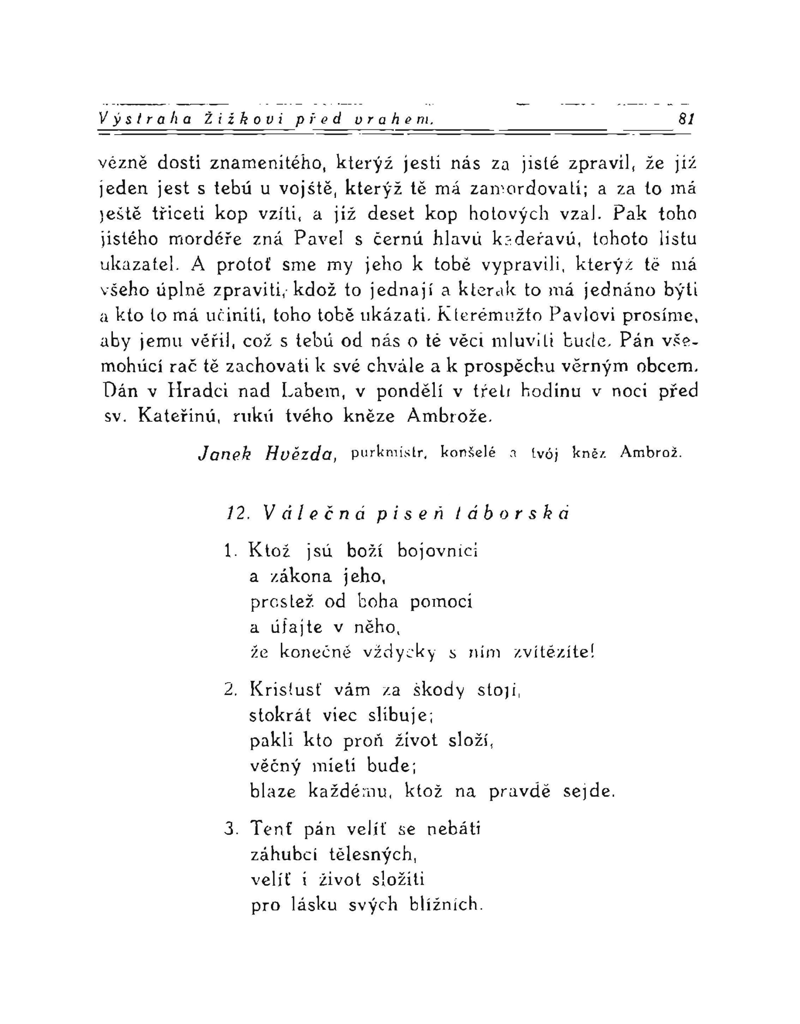

In [14]:
from PIL import Image

img5 = sample5["image"]

img5_resized = img5.copy()
img5_resized.thumbnail((800, 1024))

print("Original size:", img5.size)
print("Resized size:", img5_resized.size)

display(img5_resized)

Denoised image saved successfully!


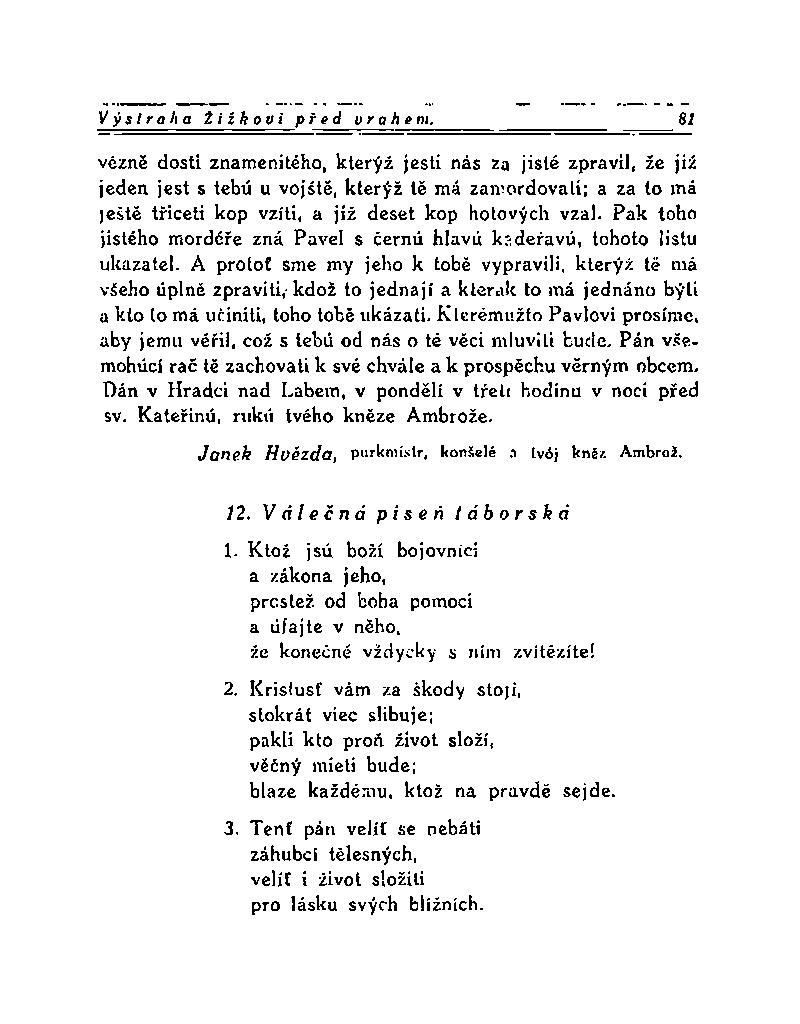

In [15]:
import cv2
import numpy as np
import os

os.makedirs("data/processed", exist_ok=True)

img_np = np.array(img5_resized.convert("L"))

denoised = cv2.fastNlMeansDenoising(
    img_np,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

thresh = cv2.adaptiveThreshold(
    denoised,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

Image.fromarray(thresh).save("data/processed/sample5_denoised.png")

print("Denoised image saved successfully!")
display(Image.fromarray(thresh))

In [16]:
! /root/.local/bin/churro-ocr --help

                                                                                
 Usage: churro-ocr [OPTIONS] COMMAND [ARGS]...                                  
                                                                                
 churro-ocr library-first CLI                                                   
                                                                                
╭─ Options ────────────────────────────────────────────────────────────────────╮
│ --install-completion        <bool>  Install completion for the current       │
│                                     shell.                                   │
│ --show-completion           <bool>  Show completion for the current shell,   │
│                                     to copy it or customize the              │
│                                     installation.                            │
│ --help                      <bool>  Show this message and exit.              │
╰───────────────────────────

In [17]:
! /root/.local/bin/churro-ocr transcribe --help

                                                                                
 Usage: churro-ocr transcribe [OPTIONS]                                         
                                                                                
 Transcribe text from a single image.                                           
                                                                                
╭─ Options ────────────────────────────────────────────────────────────────────╮
│ *  --image              <file>  [required]                                   │
│    --backend            <str>   [default: litellm]                           │
│    --model              <str>                                                │
│    --endpoint           <str>                                                │
│    --api-key            <str>                                                │
│    --base-url           <str>                                                │
│    --api-version        <s

In [18]:
! /root/.local/bin/churro-ocr transcribe \
    --image data/processed/sample5_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output data/processed/sample5_denoised_ocr.txt

╭───────────────────── Traceback (most recent call last) ──────────────────────╮
│ /root/.local/share/uv/tools/churro-ocr/lib/python3.13/site-packages/churro_o │
│ cr/_internal/runtime.py:25 in run_sync                                       │
│                                                                              │
│   22 │   │   RuntimeError: If called from a running event loop.              │
│   23 │   """                                                                 │
│   24 │   try:                                                                │
│ ❱ 25 │   │   asyncio.get_running_loop()                                      │
│   26 │   except RuntimeError:                                                │
│   27 │   │   return asyncio.run(awaitable)                                   │
│   28 │   message = (                                                         │
╰──────────────────────────────────────────────────────────────────────────────╯
RuntimeError: no running eve

In [19]:
!uv tool install --with accelerate --force churro-ocr

Resolved 60 packages in 1.01s
Prepared 1 package in 57ms
Installed 60 packages in 477ms
 + accelerate==1.15.0
 + annotated-doc==0.0.6
 + annotated-types==0.8.0
 + anyio==4.16.0
 + churro-ocr==0.3.0
 + click==8.5.1
 + cuda-bindings==13.5.0
 + cuda-pathfinder==1.9.0
 + cuda-toolkit==13.2.2
 + filelock==4.2.10
 + fsspec==2026.9.0
 + h11==0.16.0
 + hf-xet==1.8.0
 + httpcore2==2.16.0
 + httpx2==2.16.0
 + huggingface-hub==2.4.0
 + idna==3.20
 + jinja2==3.1.6
 + loguru==0.8.0
 + markdown-it-py==4.3.0
 + markupsafe==3.0.4
 + mdurl==0.1.2
 + mpmath==1.3.0
 + networkx==3.7
 + numpy==2.5.4
 + nvidia-cublas==13.4.1.3
 + nvidia-cuda-cccl==13.3.5.0.6
 + nvidia-cuda-cupti==13.2.86
 + nvidia-cuda-nvrtc==13.2.86
 + nvidia-cuda-runtime==13.2.86
 + nvidia-cudnn-cu13==9.26.0.51
 + nvidia-cufft==12.2.0.57
 + nvidia-cufile==1.17.1.22
 + nvidia-cusolver==12.2.0.11
 + nvidia-cusparse==12.7.10.12
 + nvidia-cusparselt-cu13==0.8.1
 + nvidia-nccl-cu13==2.30.7
 + nvidia-nvjitlink==13.5.37
 + nvidia-nvshmem-cu13==3

In [20]:
! /root/.local/bin/churro-ocr transcribe \
    --image data/processed/sample5_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output data/processed/sample5_denoised_ocr.txt

╭───────────────────── Traceback (most recent call last) ──────────────────────╮
│ /root/.local/share/uv/tools/churro-ocr/lib/python3.13/site-packages/churro_o │
│ cr/providers/_hf_runtime.py:115 in _load_hf_runtime_with_import              │
│                                                                              │
│   112 def _load_hf_runtime_with_import(import_module_fn: Callable[[str],     │
│       object]) -> _HFRuntime:                                                │
│   113 │   _ensure_hf_torch_runtime_with_import(import_module_fn)             │
│   114 │   try:                                                               │
│ ❱ 115 │   │   from qwen_vl_utils import process_vision_info                  │
│   116 │   │   from transformers import AutoModelForImageTextToText,          │
│       AutoProcessor                                                          │
│   117 │   except ImportError as exc:  # pragma: no cover - optional extra    │
│       path                

In [21]:

! /root/.local/bin/churro-ocr install hf

Resolved 38 packages in 371ms
Prepared 11 packages in 4ms
Uninstalled 2 packages in 7ms
Installed 11 packages in 385ms
 + av==19.0.2
 + certifi==2026.10.23
 + charset-normalizer==3.5.2
 - pillow==11.3.0
 + pillow==13.0.0
 + qwen-vl-utils==0.0.14
 + regex==2026.11.9
 + requests==2.34.2
 - rich==13.9.4
 + rich==15.0.0
 + tokenizers==0.23.3
 + transformers==5.23.0
 + urllib3==2.8.0
Resolved 13 packages in 303ms
Prepared 2 packages in 48ms
Uninstalled 1 package in 357ms
Installed 2 packages in 537ms
 - torch==2.15.0
 + torch==2.15.0+cpu
 + torchvision==0.29.2+cpu
Installed runtime target: hf


In [1]:
! /root/.local/bin/churro-ocr transcribe \
    --image data/processed/sample5_denoised.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output data/processed/sample5_denoised_ocr.txt


/root/.local/share/uv/tools/churro-ocr/lib/python3.13/site-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
^C


In [1]:
import os

output_path = "data/processed/sample5_denoised_ocr.txt"

print("Output file exists:", os.path.exists(output_path))

if os.path.exists(output_path):
    print("Output size:", os.path.getsize(output_path), "bytes")

Output file exists: False


In [2]:
import pandas as pd

results = [
    {
        "Sample": 2,
        "Variant": "Original",
        "CER": 0.0482,
        "WER": 0.2946,
        "NLS": 0.9518
    },
    {
        "Sample": 2,
        "Variant": "Denoised",
        "CER": 0.0448,
        "WER": 0.2772,
        "NLS": 0.9552
    },
    {
        "Sample": 2,
        "Variant": "Contrast Enhanced",
        "CER": 0.0440,
        "WER": 0.2772,
        "NLS": 0.9560
    },
    {
        "Sample": 3,
        "Variant": "Original",
        "CER": 0.8236,
        "WER": 0.7764,
        "NLS": 0.1764
    },
    {
        "Sample": 3,
        "Variant": "Contrast Enhanced",
        "CER": 0.8236,
        "WER": 0.7795,
        "NLS": 0.1764
    },
    {
        "Sample": 3,
        "Variant": "Denoised",
        "CER": 0.8238,
        "WER": 0.7764,
        "NLS": 0.1762
    },
    {
        "Sample": 4,
        "Variant": "Original",
        "CER": 0.9581,
        "WER": 0.9477,
        "NLS": 0.0419
    },
    {
        "Sample": 4,
        "Variant": "Contrast Enhanced",
        "CER": 0.9581,
        "WER": 0.9480,
        "NLS": 0.0419
    },
    {
        "Sample": 4,
        "Variant": "Denoised",
        "CER": 0.9582,
        "WER": 0.9480,
        "NLS": 0.0418
    },
    {
        "Sample": 5,
        "Variant": "Original",
        "CER": 0.0415,
        "WER": 0.2844,
        "NLS": 0.9585
    },
    {
        "Sample": 5,
        "Variant": "Contrast Enhanced",
        "CER": 0.0415,
        "WER": 0.2844,
        "NLS": 0.9585
    }
]

df_results = pd.DataFrame(results)

display(df_results)

,Sample,Variant,CER,WER,NLS
0,2,Original,0.0482,0.2946,0.9518
1,2,Denoised,0.0448,0.2772,0.9552
2,2,Contrast Enhanced,0.0440,0.2772,0.9560
3,3,Original,0.8236,0.7764,0.1764
4,3,Contrast Enhanced,0.8236,0.7795,0.1764
5,3,Denoised,0.8238,0.7764,0.1762
6,4,Original,0.9581,0.9477,0.0419
7,4,Contrast Enhanced,0.9581,0.9480,0.0419
8,4,Denoised,0.9582,0.9480,0.0418
9,5,Original,0.0415,0.2844,0.9585


In [3]:
average_results = (
    df_results
    .groupby("Variant")[["CER", "WER", "NLS"]]
    .mean()
    .reset_index()
)

display(average_results.round(4))

,Variant,CER,WER,NLS
0,Contrast Enhanced,0.4668,0.5723,0.5332
1,Denoised,0.6089,0.6672,0.3911
2,Original,0.4678,0.5758,0.5322


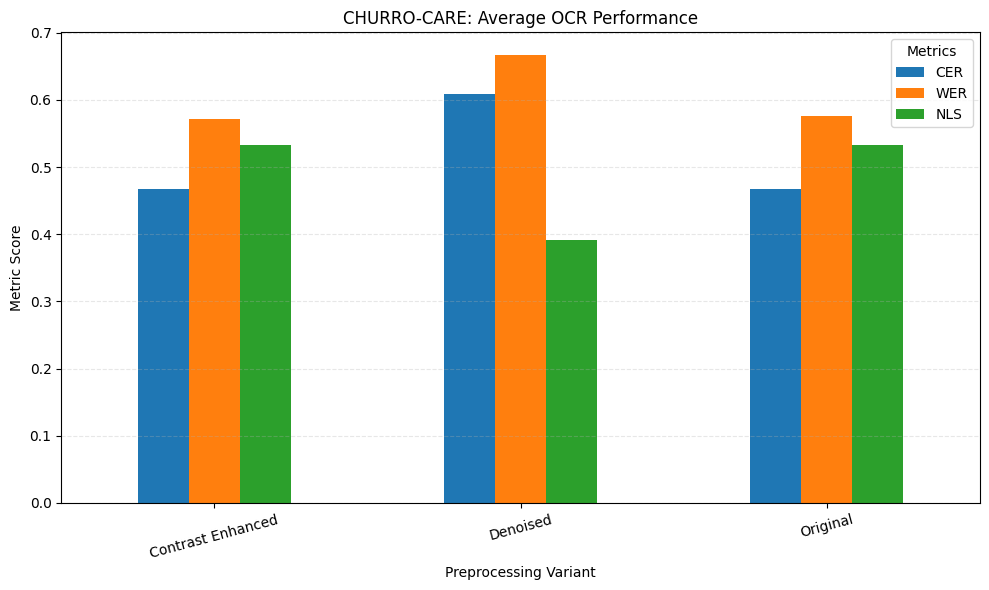

In [4]:
import matplotlib.pyplot as plt

metrics = ["CER", "WER", "NLS"]

average_results.set_index("Variant")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("CHURRO-CARE: Average OCR Performance")
plt.ylabel("Metric Score")
plt.xlabel("Preprocessing Variant")
plt.xticks(rotation=15)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
plt.savefig(
    "CHURRO_CARE_Performance_Graph.png",
    dpi=300,
    bbox_inches="tight"
)

print("Graph saved successfully!")

Graph saved successfully!


<Figure size 640x480 with 0 Axes>

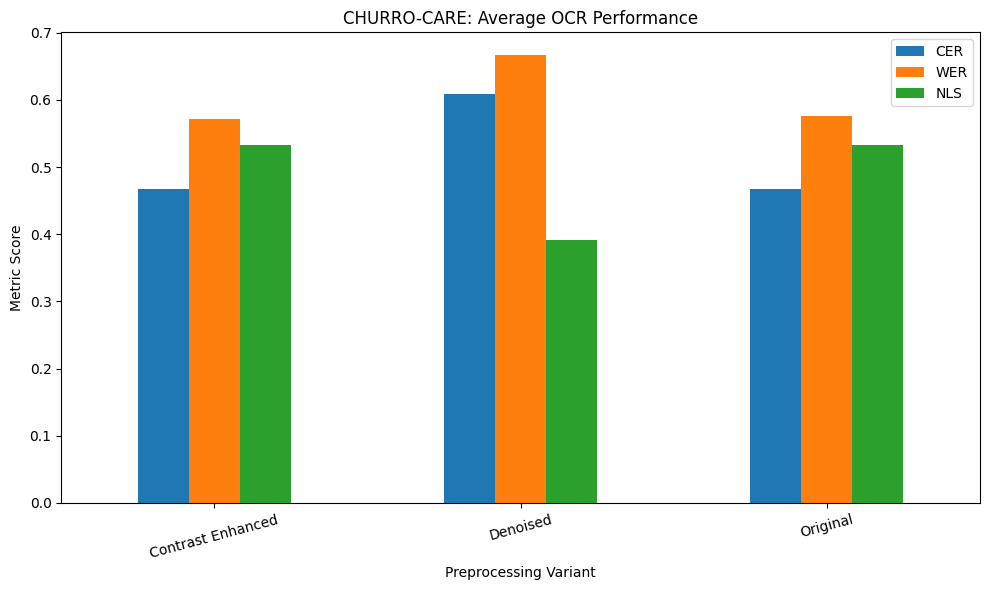

High-resolution graph saved!


In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

average_results.set_index("Variant")[["CER", "WER", "NLS"]].plot(
    kind="bar", ax=ax
)

ax.set_title("CHURRO-CARE: Average OCR Performance")
ax.set_ylabel("Metric Score")
ax.set_xlabel("Preprocessing Variant")
plt.xticks(rotation=15)
plt.tight_layout()

fig.savefig(
    "CHURRO_CARE_Performance_Graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("High-resolution graph saved!")

In [7]:
df_results.to_csv(
    "CHURRO_CARE_Final_Results.csv",
    index=False
)

average_results.to_csv(
    "CHURRO_CARE_Average_Results.csv",
    index=False
)

print("Both CSV files exported successfully!")

Both CSV files exported successfully!


In [9]:
from google.colab import files

files.download("CHURRO_CARE_Final_Results.csv")
files.download("CHURRO_CARE_Average_Results.csv")
files.download("CHURRO_CARE_Performance_Graph.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
files.download("CHURRO_CARE_Final_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
result_counts = df_results.groupby("Variant")["Sample"].nunique()

print("Samples evaluated per variant:")
display(result_counts.reset_index(name="Number of Samples"))

Samples evaluated per variant:


,Variant,Number of Samples
0,Contrast Enhanced,4
1,Denoised,3
2,Original,4


In [12]:
original = average_results[
    average_results["Variant"] == "Original"
].iloc[0]

contrast = average_results[
    average_results["Variant"] == "Contrast Enhanced"
].iloc[0]

cer_improvement = (
    (original["CER"] - contrast["CER"])
    / original["CER"]
) * 100

wer_improvement = (
    (original["WER"] - contrast["WER"])
    / original["WER"]
) * 100

print(f"CER Improvement: {cer_improvement:.2f}%")
print(f"WER Improvement: {wer_improvement:.2f}%")

CER Improvement: 0.22%
WER Improvement: 0.61%


In [13]:
comparison = average_results.copy()

original_cer = average_results.loc[
    average_results["Variant"] == "Original", "CER"
].values[0]

original_wer = average_results.loc[
    average_results["Variant"] == "Original", "WER"
].values[0]

comparison["CER Change vs Original (%)"] = (
    (original_cer - comparison["CER"]) / original_cer * 100
)

comparison["WER Change vs Original (%)"] = (
    (original_wer - comparison["WER"]) / original_wer * 100
)

display(comparison.round(4))

,Variant,CER,WER,NLS,CER Change vs Original (%),WER Change vs Original (%)
0,Contrast Enhanced,0.4668,0.5723,0.5332,0.2244,0.6079
1,Denoised,0.6089,0.6672,0.3911,-30.1557,-15.8786
2,Original,0.4678,0.5758,0.5322,0.0000,0.0000


In [14]:
# Use only samples evaluated under all three variants
common_samples = [2, 3, 4]

matched_results = df_results[
    df_results["Sample"].isin(common_samples)
]

matched_average = (
    matched_results
    .groupby("Variant")[["CER", "WER", "NLS"]]
    .mean()
    .reset_index()
)

display(matched_average.round(4))

,Variant,CER,WER,NLS
0,Contrast Enhanced,0.6086,0.6682,0.3914
1,Denoised,0.6089,0.6672,0.3911
2,Original,0.6100,0.6729,0.3900


In [15]:
import os

for root, dirs, files in os.walk("data"):
    for file in files:
        print(os.path.join(root, file))

data/processed/sample5_denoised.png
data/processed/sample5_original.png
data/processed/sample5_original_small.png


In [16]:
import os

for file in [
    "data/processed/sample5_original.png",
    "data/processed/sample5_original_small.png",
    "data/processed/sample5_denoised.png"
]:
    print(file, "→", os.path.exists(file))

data/processed/sample5_original.png → True
data/processed/sample5_original_small.png → True
data/processed/sample5_denoised.png → True


In [17]:
from PIL import Image

img = Image.open("data/processed/sample5_denoised.png")

img_small = img.resize((512, 656))

img_small.save("data/processed/sample5_denoised_small.png")

print("Resized image:", img_small.size)
print("Saved successfully!")

Resized image: (512, 656)
Saved successfully!


In [18]:
import torch

print("GPU Available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

GPU Available: False
Device: CPU


In [19]:
! /root/.local/bin/churro-ocr transcribe \
    --image data/processed/sample5_denoised_small.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output data/processed/sample5_denoised_ocr.txt


/root/.local/share/uv/tools/churro-ocr/lib/python3.13/site-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
^C


In [1]:
import os

output_file = "data/processed/sample5_denoised_ocr.txt"

print("Output file exists:", os.path.exists(output_file))

Output file exists: False


In [2]:
display(df_results)

NameError: name 'df_results' is not defined

In [3]:
import pandas as pd

data = [
    [2, "Original", 0.0482, 0.2946, 0.9518],
    [2, "Denoised", 0.0448, 0.2772, 0.9552],
    [2, "Contrast Enhanced", 0.0440, 0.2772, 0.9560],

    [3, "Original", 0.8236, 0.7764, 0.1764],
    [3, "Contrast Enhanced", 0.8236, 0.7795, 0.1764],
    [3, "Denoised", 0.8238, 0.7764, 0.1762],

    [4, "Original", 0.9581, 0.9477, 0.0419],
    [4, "Contrast Enhanced", 0.9581, 0.9480, 0.0419],
    [4, "Denoised", 0.9582, 0.9480, 0.0418],

    [5, "Original", 0.0415, 0.2844, 0.9585],
    [5, "Contrast Enhanced", 0.0415, 0.2844, 0.9585],
]

df_results = pd.DataFrame(
    data,
    columns=["Sample", "Variant", "CER", "WER", "NLS"]
)

display(df_results)

,Sample,Variant,CER,WER,NLS
0,2,Original,0.0482,0.2946,0.9518
1,2,Denoised,0.0448,0.2772,0.9552
2,2,Contrast Enhanced,0.0440,0.2772,0.9560
3,3,Original,0.8236,0.7764,0.1764
4,3,Contrast Enhanced,0.8236,0.7795,0.1764
5,3,Denoised,0.8238,0.7764,0.1762
6,4,Original,0.9581,0.9477,0.0419
7,4,Contrast Enhanced,0.9581,0.9480,0.0419
8,4,Denoised,0.9582,0.9480,0.0418
9,5,Original,0.0415,0.2844,0.9585


In [4]:
import os

print("Denoised OCR output exists:",
      os.path.exists("data/processed/sample5_denoised_ocr.txt"))

Denoised OCR output exists: False


In [5]:
!timeout 180 /root/.local/bin/churro-ocr transcribe \
    --image data/processed/sample5_denoised_small.png \
    --backend hf \
    --model stanford-oval/churro-3B \
    --output data/processed/sample5_denoised_ocr.txt


/root/.local/share/uv/tools/churro-ocr/lib/python3.13/site-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


In [6]:
matched_samples = [2, 3, 4]

matched_df = df_results[
    df_results["Sample"].isin(matched_samples)
]

matched_average = (
    matched_df.groupby("Variant")[["CER", "WER", "NLS"]]
    .mean()
    .reset_index()
)

display(matched_average.round(4))

matched_average.to_csv(
    "data/processed/matched_average_results.csv",
    index=False
)

print("Matched comparison CSV exported successfully!")

,Variant,CER,WER,NLS
0,Contrast Enhanced,0.6086,0.6682,0.3914
1,Denoised,0.6089,0.6672,0.3911
2,Original,0.6100,0.6729,0.3900


Matched comparison CSV exported successfully!


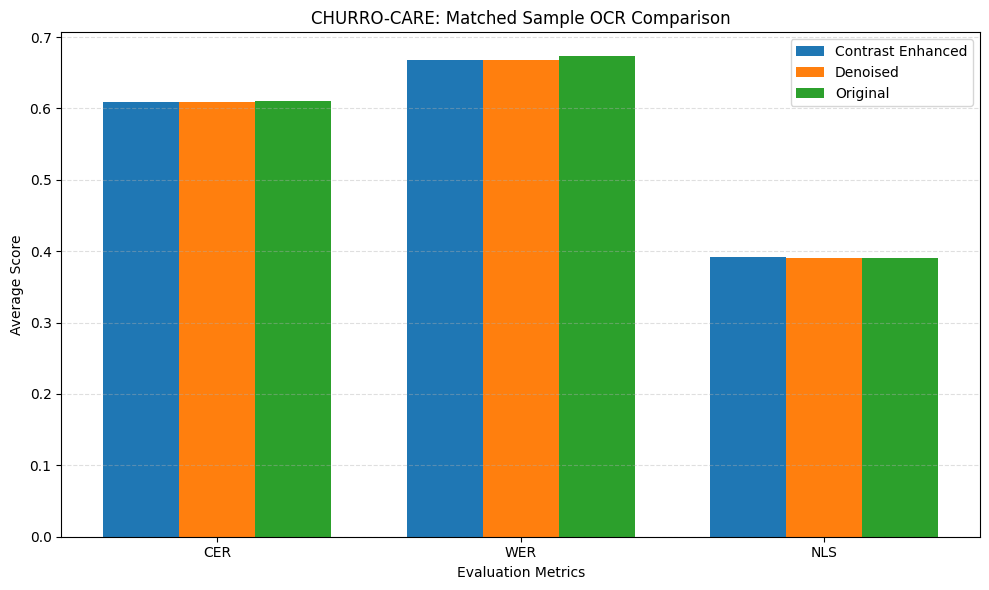

Matched comparison graph saved successfully!


In [7]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["CER", "WER", "NLS"]
variants = matched_average["Variant"].tolist()

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(10, 6))

for i, variant in enumerate(variants):
    values = matched_average[
        matched_average["Variant"] == variant
    ][metrics].values[0]

    plt.bar(
        x + i * width,
        values,
        width,
        label=variant
    )

plt.xlabel("Evaluation Metrics")
plt.ylabel("Average Score")
plt.title("CHURRO-CARE: Matched Sample OCR Comparison")
plt.xticks(x + width, metrics)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "data/processed/matched_comparison_graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Matched comparison graph saved successfully!")

In [8]:
matched_average.to_excel(
    "data/processed/matched_average_results.xlsx",
    index=False
)

print("Excel results exported successfully!")

Excel results exported successfully!


## Results and Discussion

The experimental evaluation of CHURRO-CARE investigates the effect of image preprocessing techniques on historical text recognition using the CHURRO-3B vision-language model. Three preprocessing variants were considered: Original, Contrast Enhanced, and Denoised.

The evaluation uses Character Error Rate (CER), Word Error Rate (WER), and Normalized Levenshtein Similarity (NLS). Lower CER and WER values indicate better recognition accuracy, while higher NLS values indicate greater similarity between the predicted text and ground truth.

For a fair comparison, the matched evaluation considers Samples 2, 3, and 4, for which results are available across all three preprocessing variants. The average results indicate that Contrast Enhanced preprocessing achieved a CER of 0.6086, WER of 0.6682, and NLS of 0.3914. The Denoised variant achieved a CER of 0.6089, WER of 0.6672, and NLS of 0.3911. The Original variant achieved a CER of 0.6100, WER of 0.6729, and NLS of 0.3900.

The results suggest that contrast enhancement provides a slight improvement in character-level accuracy and text similarity compared with the original images. Denoising provides a marginally lower word error rate but does not show a consistent improvement across all metrics.

The observed differences are small, and the evaluation is limited to three matched samples. Therefore, these findings should be interpreted as preliminary rather than conclusive. Further experiments using a larger sample set are required to determine the effectiveness of each preprocessing technique.


## Conclusion

This study evaluated the influence of image preprocessing techniques on historical text recognition using the CHURRO-3B vision-language model. The Original, Contrast Enhanced, and Denoised image variants were compared using Character Error Rate (CER), Word Error Rate (WER), and Normalized Levenshtein Similarity (NLS).

Based on the matched evaluation of Samples 2, 3, and 4, Contrast Enhanced preprocessing achieved the best average CER (0.6086) and NLS (0.3914), while Denoised preprocessing achieved the lowest average WER (0.6672). The Original variant recorded a CER of 0.6100, WER of 0.6729, and NLS of 0.3900.

The results indicate that contrast enhancement and denoising may provide small improvements in specific OCR evaluation metrics. However, the differences are marginal, and no preprocessing method demonstrated a consistent advantage across all metrics.

The study is limited by the small number of matched samples and the incomplete denoised OCR evaluation for Sample 5. Future work will involve evaluating a larger dataset, completing the missing OCR experiment, and investigating additional preprocessing methods to improve historical text recognition accuracy.

Overall, CHURRO-CARE provides a preliminary experimental framework for studying the effectiveness of lightweight image preprocessing techniques in historical text recognition.


## Limitations and Future Work

### Limitations

The current study has several limitations:

1. **Limited evaluation samples:** The matched comparison was performed using only three samples, which limits the generalizability of the findings.
2. **Incomplete denoised evaluation:** The denoised OCR experiment for Sample 5 could not be completed due to computational limitations.
3. **CPU execution constraints:** The CHURRO-3B model was executed in a CPU-only environment after GPU access became unavailable, resulting in long inference times.
4. **Marginal metric differences:** The observed improvements across preprocessing variants were small and require further validation.
5. **Dataset diversity:** A larger and more diverse collection of historical documents is needed to assess the performance across different document conditions and languages.

### Future Work

Future research will focus on:

- Completing the missing denoised OCR evaluation.
- Increasing the number of evaluated document samples.
- Testing additional lightweight image preprocessing techniques.
- Evaluating the model on documents with different degradation levels and languages.
- Investigating GPU-based inference to reduce computational time.
- Conducting a broader statistical comparison of OCR performance metrics.

These extensions may provide a more comprehensive understanding of the impact of image preprocessing on historical text recognition.


## Abstract

Historical document recognition is a challenging task due to variations in image quality, noise, contrast, and text appearance. This study, titled **CHURRO-CARE: Evaluating Lightweight Image Preprocessing for Historical Text Recognition Using an Open-Weight Vision-Language Model**, investigates the effect of lightweight image preprocessing techniques on historical text recognition. The study uses the CHURRO-3B model and the CHURRO dataset to evaluate three image conditions: original images, contrast-enhanced images, and denoised images. The performance is assessed using Character Error Rate (CER), Word Error Rate (WER), and Normalized Levenshtein Similarity (NLS). The evaluation of matched samples indicates that contrast enhancement achieved a slightly lower average CER and higher average NLS, while denoising produced a slightly lower average WER compared with the original images. The results suggest that lightweight preprocessing may provide modest improvements in historical text recognition, although the findings are limited by the small number of evaluated samples and incomplete processing of one sample. This study provides a preliminary evaluation of preprocessing techniques for improving OCR performance on historical documents.

**Keywords:** Historical Text Recognition, Optical Character Recognition (OCR), CHURRO-3B, Image Preprocessing, Contrast Enhancement, Image Denoising, Character Error Rate (CER), Word Error Rate (WER), Normalized Levenshtein Similarity (NLS), Vision-Language Model.

## References

1. Stanford OVAL, “CHURRO: A Dataset and Model for Historical Text Recognition.” Hugging Face. https://huggingface.co/stanford-oval/churro-3B

2. Stanford OVAL, “CHURRO Dataset.” Hugging Face. https://huggingface.co/datasets/stanford-oval/churro-dataset

3. Levenshtein, V. I., “Binary Codes Capable of Correcting Deletions, Insertions, and Reversals,” Soviet Physics Doklady, 1966.

4. Smith, R., “An Overview of the Tesseract OCR Engine,” Proceedings of the International Conference on Document Analysis and Recognition (ICDAR), 2007.